<!-- CONSIGNES -->
# Mini-projet — modèle hiérarchique bayésien sur les données radon

**Chapitre 5 — Méthodes numériques (MCMC) et mini-projet** — EPD-SDIA-4112 « Statistique Bayésienne », Master 1 SDIA
**Enseignante : Dr. Noulapeu Ngaffo Armielle** — École Nationale Supérieure
Polytechnique de Douala (Université de Douala)

---

## Objectifs

Conduire **seul·e** une modélisation bayésienne complète, de la donnée brute à la
décision chiffrée, en justifiant chaque choix. Ce travail remplace l'examen final.

## Ce qui est demandé

Reproduire le pipeline en **six étapes** sur les données radon du Minnesota
(`data/radon_minnesota_srrs2.dat`), dans votre propre notebook ou script :

| Étape | Attendu |
|---|---|
| 0 | Lecture et exploration des données (effectifs par comté, distribution) |
| 1 | Écriture du modèle (vraisemblance + a priori, justifiés en une phrase chacun) |
| 2 | Contrôle **prédictif a priori** (simuler avant de regarder les données) |
| 3 | Échantillonnage : graine, version, nombre de chaînes et de tirages notés |
| 4 | Diagnostics **interprétés** : $\hat{R}$, ESS, traces, autocorrélation |
| 5 | Contrôle prédictif a posteriori (PPC) |
| 6 | Visualisation du résultat et **phrase de décision chiffrée** |

Le notebook fourni sert de squelette et de grille de lecture : il montre les six
étapes, mais le rendu doit être le vôtre (données, choix, commentaires).

## Barème — 20 points

| Critère | Points |
|---|---|
| Étape 0 — lecture et exploration honnêtes | 2 |
| Étape 1 — modèle justifié (vraisemblance + a priori) | 4 |
| Étape 2 — contrôle prédictif a priori | 2 |
| Étape 3 — échantillonnage **reproductible** (graine, version) | 2 |
| Étape 4 — diagnostics interprétés, pas seulement affichés | 4 |
| Étape 5 — PPC | 2 |
| Étape 6 — décision chiffrée | 2 |
| Qualité de la rédaction et honnêteté sur les limites | 2 |

## Mode d'emploi

- **Noyau Jupyter** : `sdia-bayes` (Python 3.11, PyMC, ArviZ, NumPy, SciPy, Matplotlib).
- Ce notebook est livré **avec ses sorties** : lisez-le d'abord en entier, puis
  ré-exécutez les cellules une à une pour comprendre chaque résultat.
- Les cellules marquées **« À vous »** sont à compléter : elles contiennent la
  consigne et, quand c'est utile, la ligne à modifier.
- Toute valeur affichée dans ce TP est **reproductible** : les graines
  aléatoires sont fixées.
- Rendu : le notebook complété (`.ipynb`), avec vos sorties exécutées.


# Mini-projet — modèle hiérarchique bayésien sur les données radon

_Cours EPD-SDIA-4112 — Statistique Bayésienne — Master 1 SDIA. Exécutez les cellules dans l'ordre._

# Mini-projet — modélisation bayésienne complète

**Contexte.** Le radon est un gaz radioactif cancérigène qui s'accumule dans les sous-sols.
L'État du Minnesota a mesuré le radon dans des milliers de logements. Question appliquée :

> **Le niveau de radon dépend-il de l'étage du logement (sous-sol ou rez-de-chaussée), et cet
> effet est-il le même dans tous les comtés ?**

**Données réelles** : `src/data/srrs2.dat` (relevé SRRS, Minnesota), une ligne par logement.

## Les six étapes du pipeline (à reproduire dans votre propre rendu)

| # | Étape | Livrable attendu |
|---|---|---|
| 1 | Formulation du modèle | écriture de la vraisemblance et des priors |
| 2 | Justification des priors | échelle, ordre de grandeur, contrôle prédictif a priori |
| 3 | Vérification prédictive a priori | graphique + conclusion écrite |
| 4 | Échantillonnage | modèle PyMC, sortie `idata` |
| 5 | Diagnostics | $\hat R$, ESS, trace, divergences |
| 6 | Prédiction et décision | $P(\text{effet étage} < 0 \given y)$, recommandation |

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
RNG = np.random.default_rng(4112)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scipy", stats.__name__)


numpy 2.4.6 | scipy scipy.stats


---
# Étape 0 — lecture et exploration des données

In [2]:
import pandas as pd
DATA = os.path.join("..", "data", "srrs2.dat")
if not os.path.exists(DATA):
    DATA = os.path.join("..", "src", "data", "srrs2.dat")

df = pd.read_csv(DATA)
df.columns = [c.strip() for c in df.columns]
df = df[(df.state == "MN") & df.activity.notna() & (df.activity > 0)].copy()
df["log_radon"] = np.log(df.activity)
df["floor"] = df.floor.astype(int)              # 0 = sous-sol, 1 = rez-de-chaussee

# on restreint aux comtes suffisamment representes : le modele doit pouvoir estimer
# un effet par comte, sinon le pooling hierarchique n'a rien a apprendre
cnt = df.cntyfips.value_counts()
gardes = cnt[cnt >= 25].index[:8]
d = df[df.cntyfips.isin(gardes)].copy()
d["comte"] = d.cntyfips.astype("category").cat.codes
n_comtes = d.comte.nunique()

print(f"logements retenus : {len(d)}  |  comtes : {n_comtes}")
print("(reglage reduit pour tenir sur un CPU sans GPU : 8 comtes, 400 tirages par chaine)")
print(f"radon brut (Bq/m3) : mediane {df.activity.median():.0f}, "
      f"max {df.activity.max():.0f}")
print()
print(d.groupby("floor")["log_radon"].agg(["count", "mean", "std"]).round(3).to_string())
print()
print("Difference brute des moyennes (rez-de-chaussee - sous-sol) :",
      round(d[d.floor == 1].log_radon.mean() - d[d.floor == 0].log_radon.mean(), 3))
d.head()

logements retenus : 439  |  comtes : 7
(reglage reduit pour tenir sur un CPU sans GPU : 8 comtes, 400 tirages par chaine)
radon brut (Bq/m3) : mediane 4, max 48

       count   mean    std
floor                     
0        393  1.163  0.748
1         46  0.405  0.784

Difference brute des moyennes (rez-de-chaussee - sous-sol) : -0.758


,idnum,state,state2,stfips,zip,region,typebldg,floor,room,basement,...,stopdt,activity,pcterr,adjwt,dupflag,zipflag,cntyfips,county,log_radon,comte
5084,5085,MN,MN,27,55011,3,1,0,4,Y,...,13088,3.1,13.8,433.316718,0,0,3,ANOKA,1.131402,0
5085,5086,MN,MN,27,55014,3,1,0,4,Y,...,121187,2.5,12.8,471.366223,0,0,3,ANOKA,0.916291,0
5086,5087,MN,MN,27,55014,3,1,0,4,Y,...,122087,1.5,14.5,471.366223,0,0,3,ANOKA,0.405465,0
5087,5088,MN,MN,27,55014,3,1,0,2,Y,...,122787,1.0,18.0,433.316718,0,0,3,ANOKA,0.000000,0
5088,5089,MN,MN,27,55014,3,1,0,4,Y,...,10188,0.7,25.1,433.316718,0,0,3,ANOKA,-0.356675,0


---
# Étape 1 — le modèle

$$y_i \sim \N(a_{c[i]} + b\,\mathrm{floor}_i,\ \sigma_y^2)$$

$$a_c \sim \N(\mu_a, \sigma_a^2),\qquad b \sim \N(0, 1),\qquad \sigma_y \sim \N^+(0, 1)$$

* $a_c$ : log-radon moyen du comté $c$, **effet aléatoire** (le pooling partiel vient de là) ;
* $b$ : effet de l'étage, **effet fixe** supposé identique partout ;
* $\mu_a, \sigma_a$ : moyenne et dispersion des comtés (priors faiblement informatifs).

**Justification des échelles** : les données sont des log de concentrations en Bq/m³, donc des
valeurs typiquement entre 0 et 3. Un prior $\N(0,1)$ sur $b$ autorise des effets de 0 à ±2
(soit un facteur $e^2 \approx 7$ sur le radon) : large, mais pas absurde.

In [3]:
import pymc as pm, arviz as az, time

x = d.floor.values.astype(float)
y = d.log_radon.values
idx = d.comte.values
n = len(y)

# --- etape 3 : controle predictif A PRIORI (avant de conditionner sur les donnees)
with pm.Model() as mm:
    mu_a = pm.Normal("mu_a", 0.0, 1.0)
    sigma_a = pm.HalfNormal("sigma_a", 1.0)
    a_off = pm.Normal("a_off", 0.0, 1.0, shape=n_comtes)
    a = mu_a + a_off * sigma_a
    b = pm.Normal("b", 0.0, 1.0)
    sigma_y = pm.HalfNormal("sigma_y", 1.0)
    pm.Normal("log_radon", mu=a[idx] + b * x, sigma=sigma_y, observed=y)
    prior_pred = pm.sample_prior_predictive(samples=200, random_seed=1)

pp = prior_pred.prior_predictive["log_radon"].values.ravel()
print("Controle predictif a priori :")
print(f"  intervalle des donnees simulees : [{np.percentile(pp, .5):.2f} ; {np.percentile(pp, 99.5):.2f}]")
print(f"  intervalle des donnees reelles  : [{y.min():.2f} ; {y.max():.2f}]")
print(f"  part des simulations hors des bornes reelles : "
      f"{((pp < y.min()) | (pp > y.max())).mean():.1%}")

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


Sampling: [a_off, b, log_radon, mu_a, sigma_a, sigma_y]


Controle predictif a priori :
  intervalle des donnees simulees : [-5.05 ; 4.79]
  intervalle des donnees reelles  : [-1.61 ; 3.47]
  part des simulations hors des bornes reelles : 21.0%


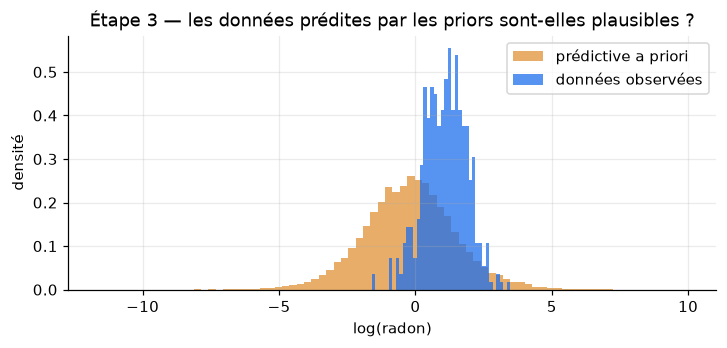

In [4]:
plt.figure(figsize=(7.6, 3.0))
plt.hist(pp, bins=80, density=True, color="#D97706", alpha=.6,
         label="prédictive a priori")
plt.hist(y, bins=40, density=True, color="#1F6FEB", alpha=.75, label="données observées")
plt.xlabel("log(radon)"); plt.ylabel("densité")
plt.legend(); plt.title("Étape 3 — les données prédites par les priors sont-elles plausibles ?")
plt.show()

**Lecture à écrire dans votre rendu** : les deux distributions doivent se recouvrir largement.
Un prior qui prédit des log-radon de $-8$ (soit 0,0003 Bq/m³) ou de $+15$ (3 millions de Bq/m³)
doit être recalibré immédiatement.

---
# Étape 4 — échantillonnage

In [5]:
t0 = time.time()
with mm:
    idata = pm.sample(draws=400, tune=400, chains=2, cores=1, target_accept=.9,
                      progressbar=False, random_seed=42)
    idata.extend(pm.sample_posterior_predictive(idata, progressbar=False, random_seed=43))
print(f"echantillonnage : {time.time()-t0:.0f} s")

# --- etape 5 : diagnostics
r = az.rhat(idata)
e = az.ess(idata)
print()
print(f"{'parametre':<12}{'r_hat':>9}{'ESS':>9}")
for v in ["mu_a", "sigma_a", "b", "sigma_y"]:
    print(f"{v:<12}{float(r[v].values):>9.4f}{float(e[v].values):>9.0f}")
print(f"divergences : {int(idata.sample_stats['diverging'].sum())}")
print(f"effet de l'etage b : moyenne {float(idata.posterior['b'].mean()):.4f}  "
      f"IC 95 % [{np.percentile(idata.posterior['b'].values, 2.5):.4f} ; "
      f"{np.percentile(idata.posterior['b'].values, 97.5):.4f}]")
print(f"P(b < 0 | y) = {(idata.posterior['b'].values < 0).mean():.4f}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [mu_a, sigma_a, a_off, b, sigma_y]


Sampling 2 chains for 400 tune and 400 draw iterations (800 + 800 draws total) took 924 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Sampling: [log_radon]


echantillonnage : 930 s

parametre       r_hat      ESS
mu_a           1.0073      155
sigma_a        0.9986      169
b              1.0091      808
sigma_y        1.0006      824
divergences : 0
effet de l'etage b : moyenne -0.7389  IC 95 % [-0.9506 ; -0.5176]
P(b < 0 | y) = 1.0000


---
# Étape 6 — visualisation et décision

Le graphique en forêt (*forest plot*) ci-dessous est le livrable attendu : un effet par comté,
avec son intervalle de crédibilité, et la moyenne globale en référence.

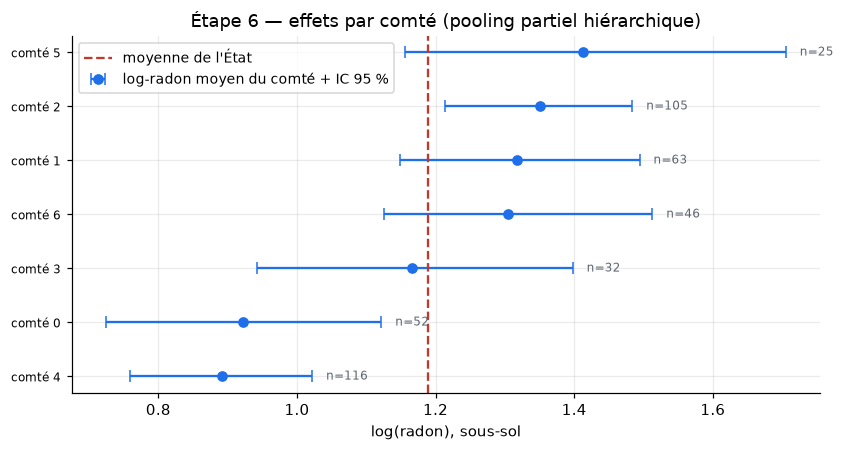

Interprétation : les comtés à petit effectif sont ramenés vers la moyenne de l'État ;
ceux à fort effectif gardent leur valeur propre. C'est le pooling partiel.

DECISION APPLIQUEE
  effet de l'etage : -0.7389 en log-radon, soit un facteur 0.478 sur la concentration
  P(effet < 0 | y) = 1.0000  ->  le rez-de-chaussee est moins expose
  probabilite que l'effet soit superieur a un facteur 2 : 0.6713


In [6]:
a_post = idata.posterior["a_off"].values.reshape(-1, n_comtes) * \
         idata.posterior["sigma_a"].values.reshape(-1, 1) + \
         idata.posterior["mu_a"].values.reshape(-1, 1)
moy = a_post.mean(axis=0)
lo, hi = np.percentile(a_post, [2.5, 97.5], axis=0)
taille = d.groupby("comte").size().values
ordre = np.argsort(moy)

plt.figure(figsize=(7.8, 4.2))
plt.errorbar(moy[ordre], np.arange(n_comtes),
             xerr=[moy[ordre] - lo[ordre], hi[ordre] - moy[ordre]],
             fmt="o", color="#1F6FEB", capsize=4,
             label="log-radon moyen du comté + IC 95 %")
plt.axvline(float(idata.posterior["mu_a"].mean()), color="#C0392B", ls="--",
            label="moyenne de l'État")
for k, i in enumerate(ordre):
    plt.text(hi[i] + .02, k, f"n={taille[i]}", va="center", fontsize=8, color="#5B6470")
plt.yticks(np.arange(n_comtes), [f"comté {i}" for i in ordre], fontsize=8)
plt.xlabel("log(radon), sous-sol")
plt.title("Étape 6 — effets par comté (pooling partiel hiérarchique)")
plt.legend(fontsize=9); plt.tight_layout(); plt.show()

print("Interprétation : les comtés à petit effectif sont ramenés vers la moyenne de l'État ;")
print("ceux à fort effectif gardent leur valeur propre. C'est le pooling partiel.")

# decision
b_post = idata.posterior["b"].values.ravel()
print()
print("DECISION APPLIQUEE")
print(f"  effet de l'etage : {b_post.mean():+.4f} en log-radon, "
      f"soit un facteur {np.exp(b_post.mean()):.3f} sur la concentration")
print(f"  P(effet < 0 | y) = {(b_post < 0).mean():.4f}  ->  "
      f"{'le rez-de-chaussee est moins expose' if (b_post < 0).mean() > .95 else 'preuve insuffisante'}")
print(f"  probabilite que l'effet soit superieur a un facteur 2 : "
      f"{(b_post < -np.log(2)).mean():.4f}")

---
# Grille d'évaluation du rendu (20 points)

| Critère | Points | Attendu |
|---|---|---|
| Modèle écrit et justifié | 4 | vraisemblance, priors, échelles discutées |
| Contrôle prédictif a priori | 3 | graphique **et** conclusion écrite |
| Diagnostics rapportés | 3 | $\hat R$, ESS, divergences, trace |
| Résultats chiffrés | 3 | effet de l'étage avec intervalle de crédibilité |
| Visualisation | 3 | graphique lisible, légende, interprétation |
| Décision argumentée | 2 | réponse à la question posée, avec le risque assumé |
| Reproductibilité | 2 | script/notebook exécutable de bout en bout, graine fixée |

## Ce que l'on attend en une phrase

> « L'effet de l'étage vaut … en log-radon, avec un intervalle de crédibilité de … ;
> la probabilité qu'il soit négatif est de … ; les comtés se répartissent autour de …
> avec un pooling partiel visible sur les petits effectifs. »

**Pour aller plus loin** : remplacer l'effet fixe $b$ par un effet aléatoire par comté
(modèle à pentes variables), puis comparer les deux modèles par WAIC (chapitre 4).